<a href="https://colab.research.google.com/github/SolonLIA/deep-learning-labs/blob/main/lab02_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lab 2**

Section 5, 6

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score )

df = pd.read_csv("power_plant.csv")
print(df.head())
print(df.shape)
print(df.columns)
print(df.describe())
print(df.info())
print(df.isnull().sum())

      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90
(9568, 5)
Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 ent

Q1. How many obervations are in the dataset?

    9568 Observations

Q2. How many input variables are used?

    4 Input Variables, AT, V, AP and RH

Q3. Which variable are you truing to predict?
  
    Net electrical power output (PE) is the variable to predict

Q4. Is this a regression of classification problem? Explain why.
  
    Regression, since all data is considered continuous numerical quantity

Section 7

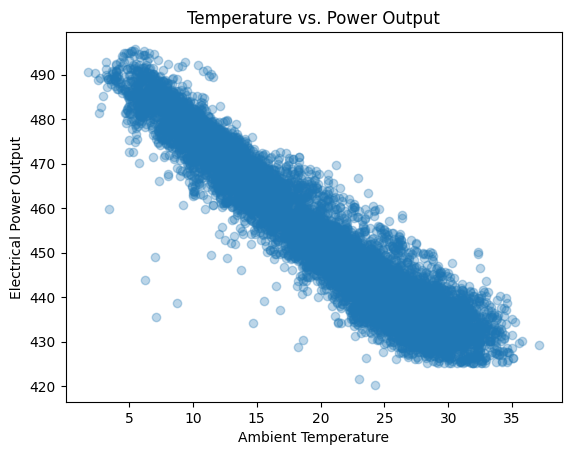

In [5]:
plt.scatter(df["AT"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Temperature")
plt.ylabel("Electrical Power Output")
plt.title("Temperature vs. Power Output")
plt.show()

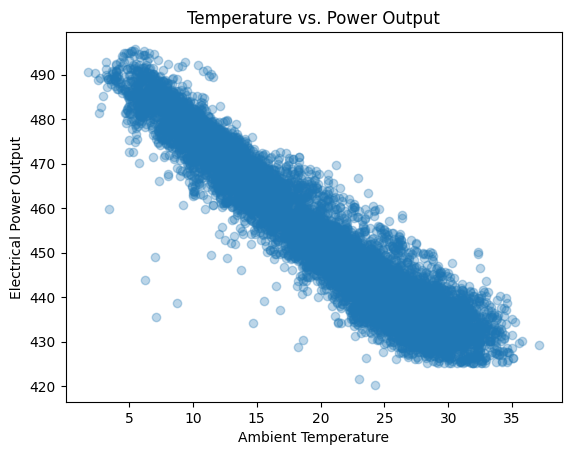

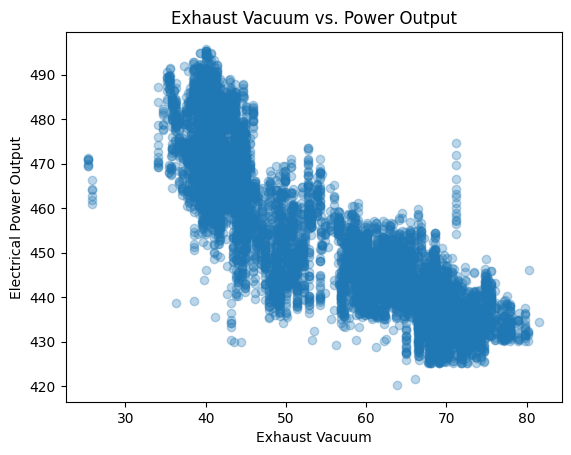

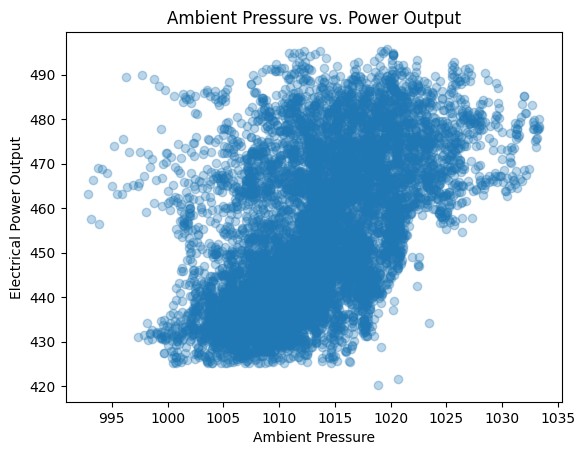

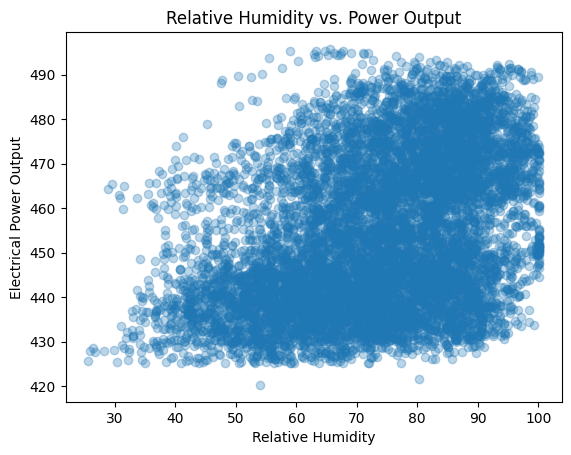

In [6]:
plt.scatter(df["AT"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Temperature")
plt.ylabel("Electrical Power Output")
plt.title("Temperature vs. Power Output")
plt.show()

plt.scatter(df["V"], df["PE"], alpha=0.3)
plt.xlabel("Exhaust Vacuum")
plt.ylabel("Electrical Power Output")
plt.title("Exhaust Vacuum vs. Power Output")
plt.show()

plt.scatter(df["AP"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Pressure")
plt.ylabel("Electrical Power Output")
plt.title("Ambient Pressure vs. Power Output")
plt.show()

plt.scatter(df["RH"], df["PE"], alpha=0.3)
plt.xlabel("Relative Humidity")
plt.ylabel("Electrical Power Output")
plt.title("Relative Humidity vs. Power Output")
plt.show()


Q5. Which variable appears to have the strongest visible relationship with power output?

    Based on the plots, Ambient Temperature (AT) appears to have the stongest visible relationship
    with power output, with PE generally decreasing as AT increases.

Q6. Is the relationship approximately linear for every variable?

    No, some of the plots showed scattered distribution across, especially AP,RH Vs PE.

Section 8, 9, 10, 11, 12

In [7]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

X_train, X_temp, y_train, y_temp = train_test_split(
X, y, test_size=0.20, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
X_temp, y_temp, test_size=0.50, random_state=42
)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 7654
Validation: 957
Testing: 957


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)



In [10]:
baseline = LinearRegression()
baseline.fit(X_train_scaled, y_train)

y_val_pred = baseline.predict(X_val_scaled)
comparison = pd.DataFrame({
"Actual": y_val.values[:10],
"Predicted": y_val_pred[:10]
})
print(comparison)

   Actual   Predicted
0  442.24  431.822122
1  483.74  480.264847
2  457.53  460.758858
3  479.43  480.243284
4  450.60  454.304563
5  445.11  448.891969
6  457.51  447.648889
7  468.58  471.239424
8  475.73  468.646234
9  452.41  445.234706


Q7. Are the predicted values reasonably close to the actual values?

    Yes. The predicted values are generally reasonably close to the actual values. The model achieves an MAE of approximately 3.61 MW and an R² of
    approximately 0.931, indicating that the linear-regression model explains most of the variation in power output,
    with some individual predictions having larger errors.

Section 13, 14, 15

MAE : 3.614783759687448
RMSE: 4.465621414739491
R^2 : 0.931069855986044


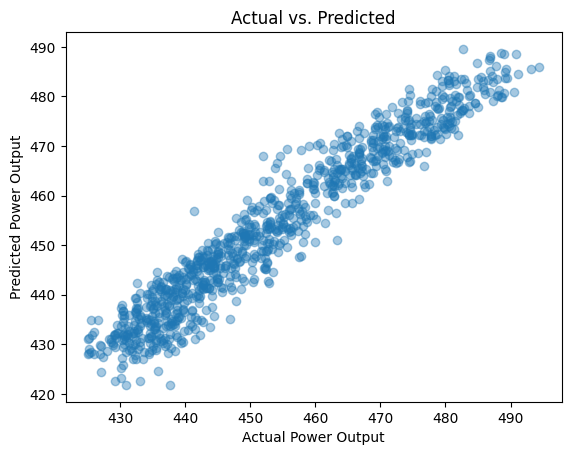

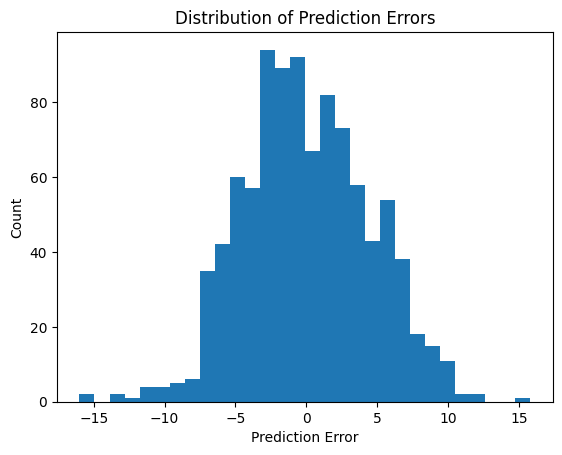

In [11]:
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(
mean_squared_error(y_val, y_val_pred)
)
r2 = r2_score(y_val, y_val_pred)
print("MAE :", mae)
print("RMSE:", rmse)
print("R^2 :", r2)

plt.scatter(y_val, y_val_pred, alpha=0.4)
plt.xlabel("Actual Power Output")
plt.ylabel("Predicted Power Output")
plt.title("Actual vs. Predicted")
plt.show()

residuals = y_val.values - y_val_pred
plt.hist(residuals, bins=30)
plt.xlabel("Prediction Error")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors")
plt.show()

Q8. Are the errors approximately centered around zero?

    Yes. The prediction errors are approximately centered around zero, suggesting that the model does not have a strong
    systematic tendency to overpredict or underpredict the power output

Q9. Are there any unusually large errors?

    Yes. Most errors are concentrated relatively close to zero, but there are a small number of unusually large errors in
    the tails of the distribution, reaching approximately 15–16 MW in magnitude.

Section 16

Q10. Would an average prediction error of approximately 4 MW be acceptable for every power-plant application? Explain briefly.

    No. An average prediction error of approximately 4 MW may be acceptable for general forecasting or preliminary planning,
    but it may be too large for applications requiring precise real-time control, dispatch, or economic optimization.
    Whether the error is acceptable depends on the accuracy requirements and consequences of prediction errors for the
    specific engineering application.

**Lab 3**

Section 17, 18, 19, 20

In [13]:
import torch
import torch.nn as nn

torch.manual_seed(42)

X_train_t = torch.tensor(
  X_train_scaled, dtype=torch.float32
)
y_train_t = torch.tensor(
  y_train.values, dtype=torch.float32
).reshape(-1, 1)
X_val_t = torch.tensor(
  X_val_scaled, dtype=torch.float32
)
y_val_t = torch.tensor(
  y_val.values, dtype=torch.float32
).reshape(-1, 1)

model = nn.Sequential(
  nn.Linear(4, 16),
  nn.ReLU(),
  nn.Linear(16, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


Q11. What would happen if the ReLU activation were removed and only linear layers remained?

    If the ReLU activation were removed, the network would consist only of linear transformations. Multiple linear layers
    without a nonlinear activation can be reduced to an equivalent single linear transformation, so the network would lose
    its ability to model nonlinear relationships and would behave similarly to a linear model.

Section 21, 22, 23

0 206703.921875 206071.421875
50 199575.3125 198690.171875
100 169655.15625 168186.484375
150 119412.78125 117839.890625
200 70603.453125 69716.4921875
250 39859.07421875 40083.42578125


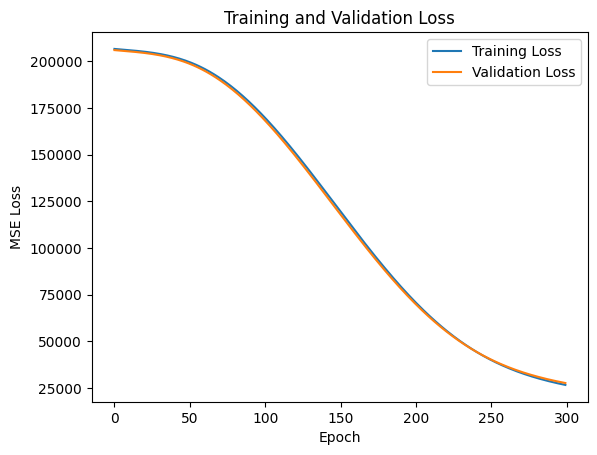

In [14]:
loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
  model.parameters(),
  lr=0.01
)

train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
      prediction,
      y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

Q12. What happened to the training loss as training progressed?

    The training loss decreased continuously as training progressed. This indicates that the neural network was learning
    the relationship between the input variables and power output and progressively reducing its prediction error.

Q13. What happened to the validation loss?

    The validation loss also decreased substantially throughout training, indicating that the model's performance on unseen
    validation data improved as training progressed.

Q14. Did the two curves behave similarly?

    Yes. The training and validation loss curves followed each other very closely and both decreased throughout training.
    Thus, no obvious overfitting.

Section 24, 25, 26

In [17]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

# Compare results with a proper table
comparison_table = pd.DataFrame({
    "Linear Regression": [mae, rmse, r2],
    "Shallow NN": [nn_mae, nn_rmse, nn_r2]
},
index=["MAE", "RMSE", "R^2"])

comparison_table = comparison_table.round(4)

display(comparison_table)

MAE : 142.9746514918089
RMSE: 166.1899313709916
R^2 : -94.46733499153383


,Linear Regression,Shallow NN
MAE,3.6148,142.9747
RMSE,4.4656,166.1899
R^2,0.9311,-94.4673


Q15. Which model has the smaller MAE?

    Linear Regression

Q16. Which model has the smaller RMSE?

    Linear Regression
    
Q17. Which model has the higher R^2?
    
    Linear Regression
    

Section 27

Q18. Does the performance improvement of your neural network justify its additional complexity? Use your results.

    No. The current shallow neural network does not justify its additional complexity because it performs substantially
    worse than linear regression. However, the learning curves indicate that the network has not yet converged, so
    further hyperparameter tuning is required before making a final comparison.

Section 28

In [18]:
# Hidden Neurons Experiment

def train_nn(hidden_neurons=16, learning_rate=0.01, epochs=300):

    # Reset seed for reproducibility
    torch.manual_seed(42)

    # Create model
    current_model = nn.Sequential(
        nn.Linear(4, hidden_neurons),
        nn.ReLU(),
        nn.Linear(hidden_neurons, 1)
    )

    loss_fn = nn.MSELoss()

    optimizer = torch.optim.Adam(
        current_model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    # Training loop
    for epoch in range(epochs):

        current_model.train()

        prediction = current_model(X_train_t)

        loss = loss_fn(
            prediction,
            y_train_t
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Validation
        current_model.eval()

        with torch.no_grad():

            val_prediction = current_model(X_val_t)

            val_loss = loss_fn(
                val_prediction,
                y_val_t
            )

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

    # Final validation predictions
    current_model.eval()

    with torch.no_grad():
        y_val_pred = current_model(X_val_t)

    y_val_pred = y_val_pred.numpy().flatten()

    # Validation metrics
    val_mae = mean_absolute_error(
        y_val,
        y_val_pred
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            y_val,
            y_val_pred
        )
    )

    val_r2 = r2_score(
        y_val,
        y_val_pred
    )

    return (
        current_model,
        train_losses,
        val_losses,
        val_mae,
        val_rmse,
        val_r2
    )

# Main Test Code

hidden_results = []

for hidden in [4, 16, 64]:

    (
        temp_model,
        temp_train_losses,
        temp_val_losses,
        temp_mae,
        temp_rmse,
        temp_r2
    ) = train_nn(
        hidden_neurons=hidden,
        learning_rate=0.01,
        epochs=300
    )

    hidden_results.append({
        "Hidden Neurons": hidden,
        "Validation MAE": temp_mae,
        "Validation RMSE": temp_rmse,
        "Validation R^2": temp_r2
    })


hidden_results_df = pd.DataFrame(hidden_results)

hidden_results_df = hidden_results_df.round(4)

display(hidden_results_df)

,Hidden Neurons,Validation MAE,Validation RMSE,Validation R^2
0,4,327.3363,359.1464,-444.8495
1,16,142.9747,166.1899,-94.4673
2,64,62.0477,73.8328,-17.8427


Q19. Does increasing the number of hidden neurons always improve validation performance?

    Not necessarily, it did appeared so with this specific experiment, but based on online research, a larger network
    does not guarantee better generalization and may lead to diminishing returns or overfitting.

Section 29

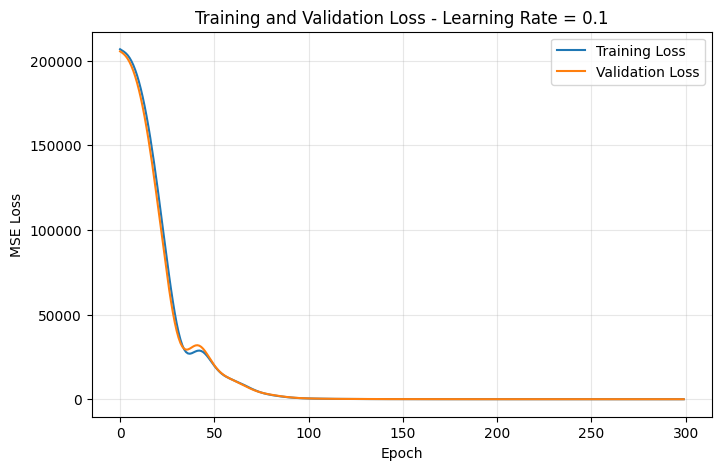

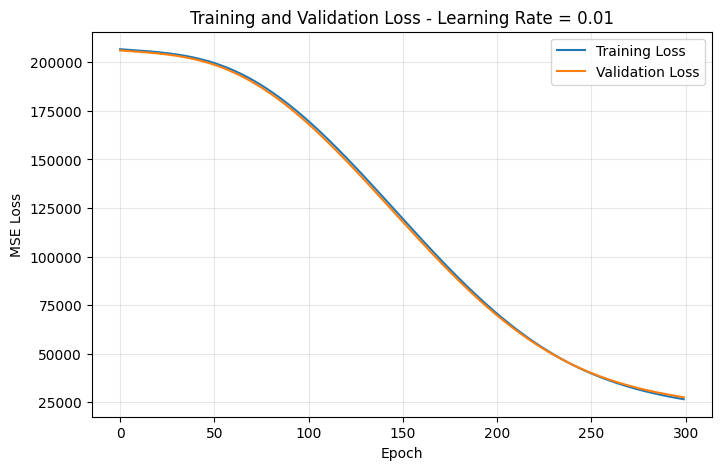

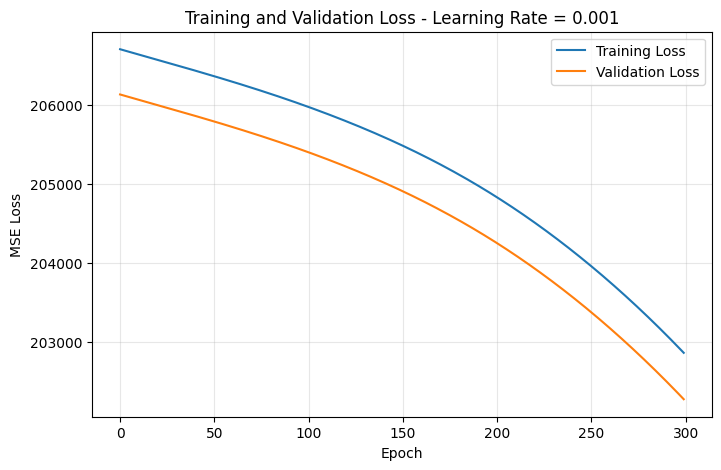

,Learning Rate,Validation MAE,Validation RMSE,Validation R^2
0,0.100,3.9477,5.1276,0.9091
1,0.010,142.9747,166.1899,-94.4673
2,0.001,449.4616,449.7571,-698.2002


In [19]:
# Learning Rate Experiment

learning_rate_results = []

for lr in [0.1, 0.01, 0.001]:

    (
        temp_model,
        temp_train_losses,
        temp_val_losses,
        temp_mae,
        temp_rmse,
        temp_r2
    ) = train_nn(
        hidden_neurons=16,
        learning_rate=lr,
        epochs=300
    )

    learning_rate_results.append({
        "Learning Rate": lr,
        "Validation MAE": temp_mae,
        "Validation RMSE": temp_rmse,
        "Validation R^2": temp_r2
    })

    # Plot learning curves
    plt.figure(figsize=(8, 5))

    plt.plot(
        temp_train_losses,
        label="Training Loss"
    )

    plt.plot(
        temp_val_losses,
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"Training and Validation Loss - Learning Rate = {lr}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()


learning_rate_results_df = pd.DataFrame(
    learning_rate_results
)

learning_rate_results_df = (
    learning_rate_results_df.round(4)
)

display(learning_rate_results_df)

Q20. What happens when the learning rate is too large?

    If the learning rate is too large, parameter updates can overshoot the minimum, causing oscillation or unstable
    convergence. In this experiment, however, the largest tested rate of 0.1 converged successfully and produced the
    best validation performance.

Q21. What happens when it is very small?

    If the learning rate is too small, parameter updates are very small and convergence becomes slow. This was
    clearly observed at 0.001, where the loss decreased only slightly over 300 epochs and validation performance
    remained very poor.

Section 30, 31, 32, 33

In [20]:
# Final Model Selection

selected_hidden = 16
selected_lr = 0.1
selected_epochs = 300

(
    model,
    final_train_losses,
    final_val_losses,
    final_val_mae,
    final_val_rmse,
    final_val_r2
) = train_nn(
    hidden_neurons=selected_hidden,
    learning_rate=selected_lr,
    epochs=selected_epochs
)

final_configuration = pd.DataFrame({
    "Configuration": [
        "Hidden Neurons",
        "Learning Rate",
        "Epochs"
    ],
    "Selected Value": [
        selected_hidden,
        selected_lr,
        selected_epochs
    ]
})

display(final_configuration)

# Final Test Evaluation

X_test_t = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

model.eval()

with torch.no_grad():
    y_test_nn = model(X_test_t)

y_test_nn = y_test_nn.numpy().flatten()

# Shallow Neural Network test metrics

nn_test_mae = mean_absolute_error(
    y_test,
    y_test_nn
)

nn_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_nn
    )
)

nn_test_r2 = r2_score(
    y_test,
    y_test_nn
)

# Linear Regression test predictions

y_test_lr = baseline.predict(X_test_scaled)

lr_test_mae = mean_absolute_error(
    y_test,
    y_test_lr
)

lr_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_lr
    )
)

lr_test_r2 = r2_score(
    y_test,
    y_test_lr
)

# Final test comparison table

test_results = pd.DataFrame({
    "Linear Regression": [
        lr_test_mae,
        lr_test_rmse,
        lr_test_r2
    ],
    "Shallow NN": [
        nn_test_mae,
        nn_test_rmse,
        nn_test_r2
    ]
},
index=[
    "Test MAE",
    "Test RMSE",
    "Test R^2"
])

test_results = test_results.round(4)

display(test_results)

,Configuration,Selected Value
0,Hidden Neurons,16.0
1,Learning Rate,0.1
2,Epochs,300.0


,Linear Regression,Shallow NN
Test MAE,3.5770,3.9102
Test RMSE,4.5393,5.2008
Test R^2,0.9291,0.9069


In [22]:
# Largest absolute prediction errors on the final test set

lr_errors = np.abs(y_test.values - y_test_lr)
nn_errors = np.abs(y_test.values - y_test_nn)

lr_max_idx = np.argmax(lr_errors)
nn_max_idx = np.argmax(nn_errors)

largest_error_results = pd.DataFrame({
    "Model": ["Linear Regression", "Shallow NN"],
    "Largest Error (MW)": [
        lr_errors[lr_max_idx],
        nn_errors[nn_max_idx]
    ],
    "Actual PE (MW)": [
        y_test.values[lr_max_idx],
        y_test.values[nn_max_idx]
    ],
    "Predicted PE (MW)": [
        y_test_lr[lr_max_idx],
        y_test_nn[nn_max_idx]
    ]
})

display(largest_error_results.round(4))

,Model,Largest Error (MW),Actual PE (MW),Predicted PE (MW)
0,Linear Regression,28.4554,459.86,488.3154
1,Shallow NN,30.8292,427.84,458.6692


Q22. Which model performed better on the final test set?

    The linear regression model performed slightly better on the final test set. It achieved a lower MAE of 3.5770 MW,
    a lower RMSE of 4.5393 MW, and a higher R² of 0.9291 compared with the shallow neural network.

Q23. Was the improvement substantial or small?

    The difference in performance was relatively small, but it consistently favored linear regression. The SNN had an
    MAE about 0.33 MW higher, an RMSE about 0.66 MW higher, and an R² about 0.022 lower than the linear-regression model.
    Therefore, the additional neural-network complexity did not provide an improvement in final test performance.

Q24. What is the largest prediction error you observed?

    The largest absolute prediction error observed on the final test set was approximately 30.83 MW, produced by the SNN.
    For that case, the actual power output was 427.84 MW while the model predicted 458.67 MW.

Q25. What engineering conditions might make prediction more difficult? Consider factors not represented in the four inputs.

    Equipment degradation or fouling, turbine and condenser condition, cooling-water temperature, plant load or operating mode,
    maintenance state, sensor errors, and other changes in equipment efficiency could all lead to more difficult prediction
    with the current model.

Section 34, 35

R1. Why is low training error alone insufficient evidence that a model is useful?

    This alone only indicates the model performed well with the existing data given, but once new data arrives,
    it might deviate from reliable predictions.

R2. Why should preprocessing parameters such as normalization statistics be calculated using only training data?

    Preprocessing parameters should be calculated using only the training data to prevent information from the validation
    or test sets from influencing model development, such as data leakage.

R3. What is the purpose of the validation dataset?

    The validation dataset is used during model development to evaluate and compare different configurations, such as
    hidden-layer size, learning rate, or number of epochs. It helps select the model configuration without using the
    final test data.

R4. What is the purpose of the test dataset?

    The test dataset provides an independent estimate of how well the finalized model performs on unseen data.

R5. Why might a simpler model sometimes be preferable even if a neural network performs slightly better?

    A simpler model may require less computation, less tuning, and less debugging, while also being easier to interpret
    and maintain, which could be suitable to use on environment with limited resources.
R6. What evidence would you want before deploying this model in a real power plant?

    The model needs to demonstrate a consistent performance over large amounts of unseen operating data and the full
    range of expected plant conditions. On top of that, the worst-case prediction errors, robustness to data noise
    and abnormal operating conditions, and accuracy of the model along the equipment condition change needs to be verified.